## MCF-7 in co-culture with *Fusobacterium nucleatum* Modeling with MICOM

This script corresponds to the modeling of an MCF-7 community in co-culture with *Fusobacterium nucleatum*. This simulation aims to create a community in which three MCF-7 subpopulations and *F. nucleatum* interact within the same medium, simulating an experimental co-culture such as the one reported in Zhao et al. (2025) work (paper [here](https://onlinelibrary.wiley.com/doi/10.1002/ctm2.70273))

##### import packages

In [8]:
import micom
import pandas as pd
import numpy as np
import osqp
import pickle
import cobra
import cobra.io
import matplotlib.pyplot as plt
import logging
from pathlib import Path
from micom import load_pickle
from micom.media import minimal_medium
from micom.workflows import workflow
from micom import Community

In [4]:
print("MICOM_version:", micom.__version__) #MICOM version 0.37.1

MICOM_version: 0.37.1


---
### **I. Community**

#### **1. Load reconstructions**

The MCF-7 reconstructions were obtained from the work Modeling Cancer Metabolism Heterogeneity with MICOM by Arellano and Resendis (GitHub [here](https://github.com/resendislab/Modeling_Heterogeneity_Cancer_Metabolism_MICOM/tree/main)). In this study, three cellular subpopulations were identified within an MCF-7 spheroid:

Model A – Invasive Population

Model B – Reservoir Population

Model C – Proliferating Population

The *F. nucleatum* reconstruction was obtained from AGORA2 database

In [5]:
A = cobra.io.read_sbml_model('ModelA.xml')
B = cobra.io.read_sbml_model('ModelB.xml')
C = cobra.io.read_sbml_model('ModelC.xml')

In [6]:
F = cobra.io.read_sbml_model('Fusobacterium_nucleatum.xml')

#### **2. Model conditions**

##### **A. Abundance**
**Cancer 50%**
* Population_A (C_A: 4.88%) 
* Population_B (C_B: 19.55%) 
* Population_C (C_C: 22.65%)

**Fusubacterium 50%**
* Fusubacterium (FN: 50% )

##### **B. Oxigen gradients**
* 0.16 mmol/gDW/hr - Normoxia

In [9]:
A2 = A.copy()
A2.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(A2, "A_1.xml")

B2 = B.copy()
B2.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(B2, "B_1.xml")

C2 = C.copy()
C2.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(C2, "C_1.xml")

NameError: name 'write_sbml_model' is not defined

In [10]:
FN = F.copy()
FN.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(FN, "F_1.xml")

NameError: name 'write_sbml_model' is not defined

#### **3. Create community**

In [11]:
TyF = {'id': ['CanA', 'CanB', 'CanC','Fusobacterium'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0.50]
    }

df_TyF = pd.DataFrame(data=TyF)
df_TyF

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fusobacterium,F_1.xml,0.50000


In [12]:
TyF = micom.Community (df_TyF, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(TyF.reactions)))

Output()

build a community with a total of 4120 reactions.


#### **4. New medium**

The community growth medium will be modified to a medium composed of: the minimum medium + McCoys 5A

In [13]:
TyF.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

#### **5. Optimize the community**

In [14]:
sol_TyF = TyF.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_TyF

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.050317,0.010104,1126,982
CanB,0.201370,0.040440,742,616
CanC,0.233301,0.046852,1032,807
Fusobacterium,0.515013,0.118586,1029,935
medium,NaN,NaN,191,191


In [15]:
len(TyF.reactions)

4120

In [12]:
from cobra.flux_analysis import (single_gene_deletion, single_reaction_deletion)

In [14]:
deletion=single_reaction_deletion(TyF, TyF.reactions [:4120])

In [15]:
deletion.to_csv("deletion.csv")

#### **6. Doubling speed**

Once the community has been constructed, the next step is to estimate the doubling times to evaluate whether they are consistent with experimental data.

##### Growth Rate

In [16]:
fluxes = sol_TyF.fluxes
flux_cancer_A_biomass = fluxes.loc['CanA', "biomass_reaction"]
flux_cancer_B_biomass = fluxes.loc['CanB', "biomass_reaction"]
flux_cancer_C_biomass = fluxes.loc['CanC', "biomass_reaction"]
flux_fuso_biomass = fluxes.loc["Fusobacterium", "EX_biomass_e"]

In [17]:
print("Growth Rate of the community:", sol_TyF.growth_rate, "mmol/gDW*hr")
print("Growth Rate of the A:", flux_cancer_A_biomass, "mmol/gDW*hr")
print("Growth Rate of the B:", flux_cancer_B_biomass, "mmol/gDW*hr")
print("Growth Rate of the C:", flux_cancer_C_biomass, "mmol/gDW*hr")
print("Growth Rate of the fusobacterium:", flux_fuso_biomass, "mmol/gDW*hr")

Growth Rate of the community: 0.08065571829421905 mmol/gDW*hr
Growth Rate of the A: 0.010104283385970714 mmol/gDW*hr
Growth Rate of the B: 0.04044005618080279 mmol/gDW*hr
Growth Rate of the C: 0.04685214382998106 mmol/gDW*hr
Growth Rate of the fusobacterium: 0.11858593660340047 mmol/gDW*hr


##### Doubling speed

In [18]:
import math
r = math.log(2)

print("Community Cancer y Fusobacterium:")
print("doubling speed - Community:", r/sol_TyF.growth_rate, "hrs")
print("doubling speed - Cancer A:", r/ flux_cancer_A_biomass, "hrs")
print("doubling speed - Cancer B:", r/ flux_cancer_B_biomass, "hrs")
print("doubling speed - Cancer C:", r/ flux_cancer_C_biomass, "hrs")
print("doubling speed - Fusobacterium:", r/ flux_fuso_biomass, "hrs")

Community Cancer y Fusobacterium:
doubling speed - Community: 8.593900038574526 hrs
doubling speed - Cancer A: 68.59934090153736 hrs
doubling speed - Cancer B: 17.14011418433656 hrs
doubling speed - Cancer C: 14.79435355349513 hrs
doubling speed - Fusobacterium: 5.845104406251063 hrs


---
### **II. Community without *F. nucleatum***

#### **1. Create community**

Next, the simulation will be performed in the absence of *F. nucleatum*, using the same medium. Additionally, reconstructions with normoxic oxygen levels obtained in step I.2 will be used.

In [19]:
Tumor = {'id': ['CanA', 'CanB', 'CanC','Fuso'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0] #the abundance for Fusobacterium will be 0.
    }

df_T = pd.DataFrame(data=Tumor)
df_T

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fuso,F_1.xml,0.00000


In [20]:
Tumor = micom.Community (df_T, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(Tumor.reactions)))

Output()

build a community with a total of 3017 reactions.


#### **2. Add medium**

In [21]:
Tumor.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

#### **3. Optimize the community**

In [22]:
sol_Tumor = Tumor.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_Tumor

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.103749,0.005274,1126,982
CanB,0.415207,0.021110,742,616
CanC,0.481045,0.025966,1032,807
medium,NaN,NaN,117,117


In [21]:
len (Tumor.reactions)

3017

In [22]:
deletion_t=single_reaction_deletion(Tumor, Tumor.reactions [:3017])

In [23]:
deletion_t.to_csv("deletion_t.csv")

#### **4. Doubling speed**

##### Growth rate

In [23]:
fluxes = sol_Tumor.fluxes
flux_cancer_A_biomass1 = fluxes.loc['CanA', "biomass_reaction"]
flux_cancer_B_biomass1 = fluxes.loc['CanB', "biomass_reaction"]
flux_cancer_C_biomass1 = fluxes.loc['CanC', "biomass_reaction"]

In [24]:
print("Growth Rate of the community:", sol_Tumor.growth_rate, "mmol/gDW*hr")
print("Growth Rate of the A:", flux_cancer_A_biomass1, "mmol/gDW*hr")
print("Growth Rate of the B:", flux_cancer_B_biomass1, "mmol/gDW*hr")
print("Growth Rate of the C:", flux_cancer_C_biomass1, "mmol/gDW*hr")

Growth Rate of the community: 0.021803117845899642 mmol/gDW*hr
Growth Rate of the A: 0.00527436450893861 mmol/gDW*hr
Growth Rate of the B: 0.02111046184142107 mmol/gDW*hr
Growth Rate of the C: 0.025965783847604305 mmol/gDW*hr


##### Doubling Speed

In [25]:
import math
r = math.log(2)

print("Community Cancer y Fusobacterium:")
print("doubling speed - Community:", r/sol_Tumor.growth_rate, "hrs")
print("doubling speed - Cancer A:", r/ flux_cancer_A_biomass1, "hrs")
print("doubling speed - Cancer B:", r/ flux_cancer_B_biomass1, "hrs")
print("doubling speed - Cancer C:", r/ flux_cancer_C_biomass1, "hrs")

Community Cancer y Fusobacterium:
doubling speed - Community: 31.79119543631236 hrs
doubling speed - Cancer A: 131.41814134864015 hrs
doubling speed - Cancer B: 32.83429731508354 hrs
doubling speed - Cancer C: 26.694637243693204 hrs


---
### **III. Plots**

#### **1. Community with *F. nucleatum***

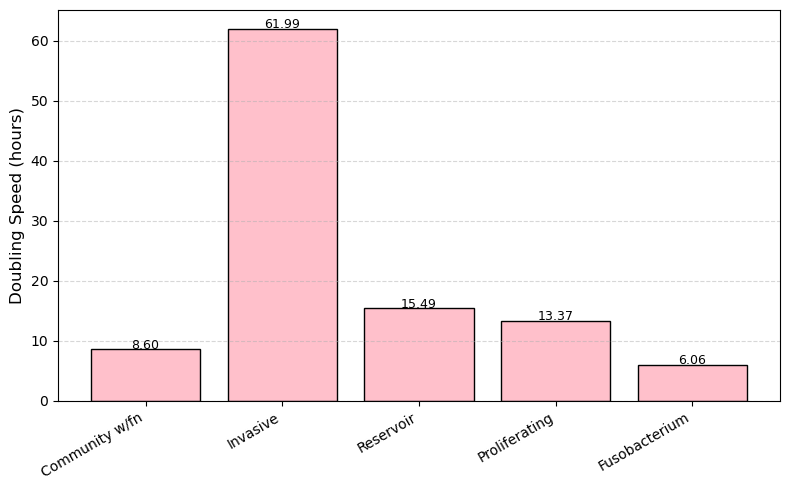

In [21]:
import matplotlib.pyplot as plt


# Calculate the doubling speed (in hours)
doubling_times = {
    "Community w/fn": r / sol_TyF.growth_rate,
    "Invasive": r / flux_cancer_A_biomass,
    "Reservoir": r / flux_cancer_B_biomass,
    "Proliferating": r / flux_cancer_C_biomass,
    "Fusobacterium": r / flux_fuso_biomass
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

# Create the graph
plt.figure(figsize=(8,5))
plt.bar(labels, values, color="pink", edgecolor="black")

# 
plt.ylabel("Doubling Speed (hours)", fontsize=12)
#plt.title("Doubling Speed - Community, Cancer, Fusobacterium", fontsize=13)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
#
for i, v in enumerate(values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

#### **2. Community without *F. nucleatum***

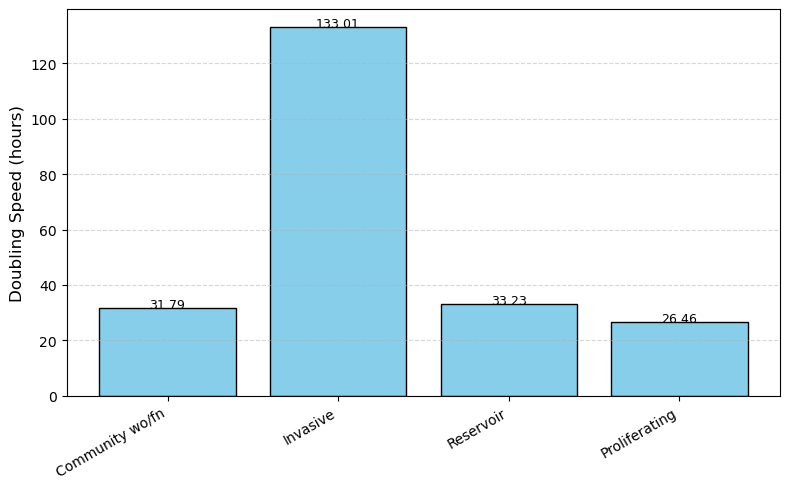

In [22]:
import matplotlib.pyplot as plt


# Calculate the doubling speed (in hours)
doubling_times = {
    "Community wo/fn": r / sol_Tumor.growth_rate,
    "Invasive": r / flux_cancer_A_biomass1,
    "Reservoir": r / flux_cancer_B_biomass1,
    "Proliferating": r / flux_cancer_C_biomass1,
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

# Create the graph
plt.figure(figsize=(8,5))
plt.bar(labels, values, color="skyblue", edgecolor="black")

# 
plt.ylabel("Doubling Speed (hours)", fontsize=12)
#plt.title("Doubling Speed - Community, Cancer, Fusobacterium", fontsize=13)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 
for i, v in enumerate(values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

#### **3. Doubling Speed Comparison Between Communities**

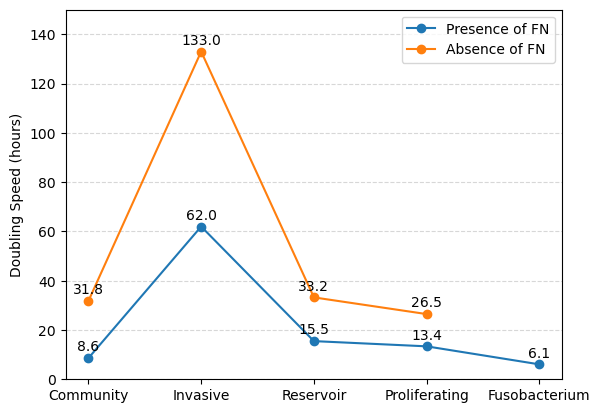

In [35]:
doubling_times = {
    "Community": r / sol_TyF.growth_rate,
    "Invasive": r / flux_cancer_A_biomass,
    "Reservoir": r / flux_cancer_B_biomass,
    "Proliferating": r / flux_cancer_C_biomass,
    "Fusobacterium": r / flux_fuso_biomass
}

doubling_times1 = {
    "Community": r / sol_Tumor.growth_rate,
    "Invasive": r / flux_cancer_A_biomass1,
    "Reservoir": r / flux_cancer_B_biomass1,
    "Proliferating": r / flux_cancer_C_biomass1,
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

labels1 = list(doubling_times1.keys())
values1 = list(doubling_times1.values())


fig, ax = plt.subplots()
ax.plot(labels, values, label="Presence of FN",marker='o')
ax.plot(labels1, values1, label="Absence of FN",marker='o')

for x, y in zip(labels, values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

for x, y in zip(labels1, values1):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()
ax.set_ylim(0, 150)
ax.set_ylabel('Doubling Speed (hours)')
plt.savefig("plots/tiempo_duplicacion.png", dpi=300, bbox_inches="tight")
plt.show()


In [2]:
import math
r = math.log(2)

print("Community Cancer y Fusobacterium:")
print("doubling speed - Community:", r/0.0447, "hrs")

Community Cancer y Fusobacterium:
doubling speed - Community: 15.506648334674392 hrs


In [19]:
r/0.04088

16.955655101759913

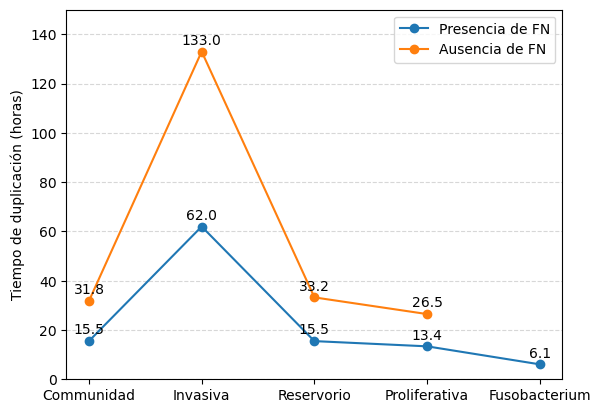

In [1]:
import matplotlib.pyplot as plt
import numpy as np
doubling_times = {
    "Communidad": 15.506648334674392,
    "Invasiva": 61.991301705470775,
    "Reservorio": 15.48886553396319,
    "Proliferativa": 13.36897748763418,
    "Fusobacterium": 6.055992862475438
}

doubling_times1 = {
    "Communidad": 31.79119543638259,
    "Invasiva": 133.01307210210072,
    "Reservorio": 33.23217931044501,
    "Proliferativa": 26.45844096489113,
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

labels1 = list(doubling_times1.keys())
values1 = list(doubling_times1.values())


fig, ax = plt.subplots()
ax.plot(labels, values, label="Presencia de FN",marker='o')
ax.plot(labels1, values1, label="Ausencia de FN",marker='o')

for x, y in zip(labels, values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

for x, y in zip(labels1, values1):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()
ax.set_ylim(0, 150)
ax.set_ylabel('Tiempo de duplicación (horas)')
plt.savefig("plots/tiempo_duplicacion_new_ESPAÑOL.png", dpi=300, bbox_inches="tight")
plt.show()

### **IV. Save to CSV files**

In [35]:
fluxesTyF = sol_TyF.fluxes
fluxesTyF.to_csv('TyF.csv')

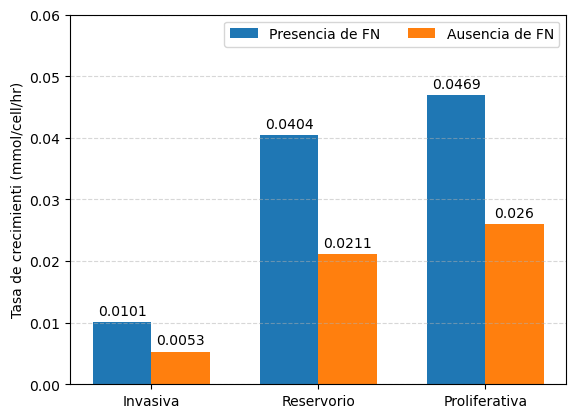

In [1]:
## Growth rates - Plot 
import matplotlib.pyplot as plt
import numpy as np

population = ( "Invasiva", "Reservorio", "Proliferativa")
population_gr = {
    'Presencia de FN': (0.0101, 0.0404, 0.0469),
    'Ausencia de FN': (0.0053,0.0211,0.0260),
}

x = np.arange(len(population))  # the label locations
width = 0.35  # the width of the bars
multiplier = 0

fig, ax = plt.subplots()

for attribute, measurement in population_gr.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

ax.set_ylabel('Tasa de crecimienti (mmol/cell/hr)')
ax.set_xticks(x + width / 2, population)
ax.legend(loc='upper right', ncols=2)
ax.set_ylim(0, 0.06)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig("plots/growth_rates_ESPAÑOL.png", dpi=300, bbox_inches="tight")
plt.show()

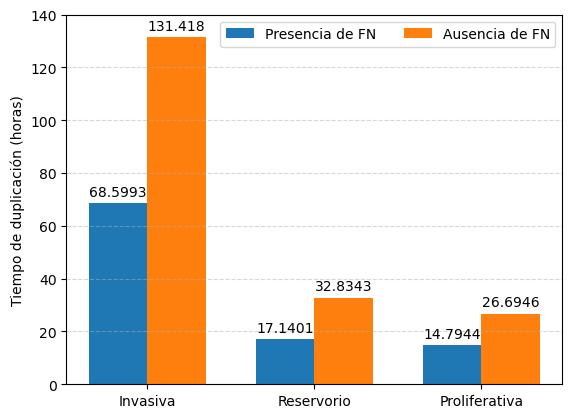

In [2]:
## doubling time - Plot 
import matplotlib.pyplot as plt
import numpy as np

population = ("Invasiva", "Reservorio", "Proliferativa")
population_dt = {
    'Presencia de FN': (68.5993,17.1401,14.7944),
    'Ausencia de FN': (131.4181,32.8343,26.6946),
}

x = np.arange(len(population))  # the label locations
width = 0.35  # the width of the bars
multiplier = 0

fig, ax = plt.subplots()

for attribute, measurement in population_dt.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

ax.set_ylabel('Tiempo de duplicación (horas)')
ax.set_xticks(x + width / 2, population)
ax.legend(loc='upper right', ncols=2)
ax.set_ylim(0, 140)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig("plots/doubling_time_ESPAÑOL.png", dpi=300, bbox_inches="tight")
plt.show()

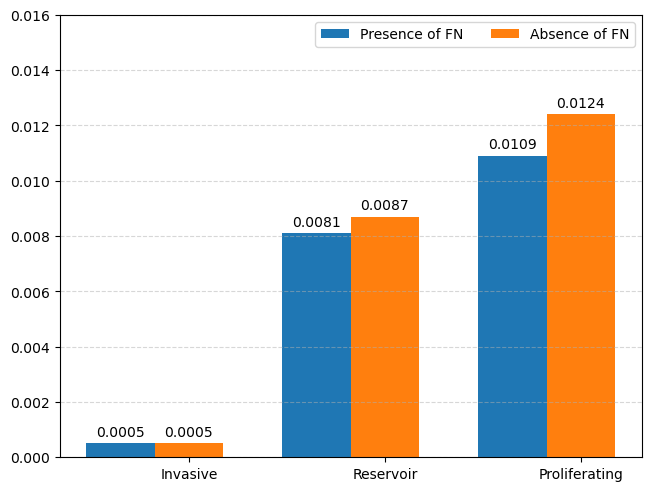

<Figure size 1600x1000 with 0 Axes>

In [21]:
## abundance*growth_rate - Plot 
import matplotlib.pyplot as plt
import numpy as np

population = ( "Invasive", "Reservoir", "Proliferating")
population_ag = {
    'Presence of FN': (0.0005,0.0081,0.0109),
    'Absence of FN': (0.0005,0.0087,0.0124),
}

x = np.arange(len(population))  # the label locations
width = 0.35  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in population_ag.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

plt.figure(figsize=(16,10))
#ax.set_ylabel('Doubling time (hours)')
ax.set_xticks(x + width, population)
ax.legend(loc='upper right', ncols=2)
ax.set_ylim(0, 0.016)
ax.grid(axis='y', linestyle='--', alpha=0.5)
#plt.savefig("plots/individual_growth.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
import math
r = math.log(2)

In [26]:
r/0.08065575584

8.593896038057949